# Two-species model
## Model equations

The ODE system is

$$
\begin{aligned}
\dot{F}_{f,i} &= -\alpha_i F_{f,i} + \left(1+b_{N,i}\right) \beta_i C_{2,N,i} + \left(1+b_{I,i}\right) \beta_i C_{2,I,i} - d_i \left(N_i + \rho_{ij} N_j\right) F_{f,i} \\
\dot{C}_{1,N,i} &= \alpha_i \frac{M_{N,i}}{M_{N,i}+M_{I,i}} F_{f,i} - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right) + \gamma_i M_{I,i}\right) C_{1,N,i} \\
\dot{C}_{2,N,i} &= \beta_i C_{1,N,i} - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right) + \gamma_i M_{I,i}\right) C_{2,N,i} \\
\dot{C}_{1,I,i} &= \alpha_i \frac{M_{I,i}}{M_{N,i}+M_{I,i}} F_{f,i} + \gamma_i M_{I,i} \left(C_{1,N,i} + C_{2,N,i} + C_{2,I,i}\right) - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right)\right) C_{1,I,i} \\
\dot{C}_{2,I,i} &= \beta_i C_{1,I,i} - \left(\beta_i + d_i \left(N_i + \rho_{ij} N_j\right) + \gamma_i M_{I,i}\right) C_{2,I,i} \\
\dot{M}_{N,i} &= b_{N,i} \beta_i C_{2,N,i} - d_i \left(N_i + \rho_{ij} N_j\right) M_{N,i} \\
\dot{M}_{I,i} &= b_{I,i} \beta_i C_{2,I,i} - d_i \left(N_i + \rho_{ij} N_j\right) M_{I,i}
\end{aligned}
$$

where

$$
\begin{aligned}
N_i &= F_{f,i} + C_{1,N,i} + C_{2,N,i} + C_{1,I,i} + C_{2,I,i} + M_{N,i} + M_{I,i} \\
b_{I,i} &= \left(1-s_i\right) b_{N,i} \\
p_i &= \frac{M_{I,i}}{M_{N,i} + M_{I,i}}
\end{aligned}
$$


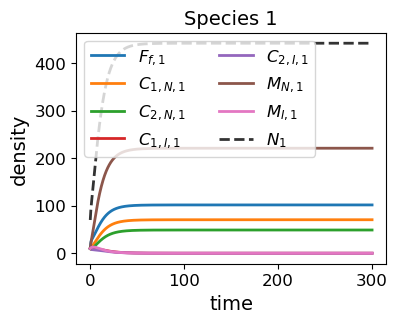

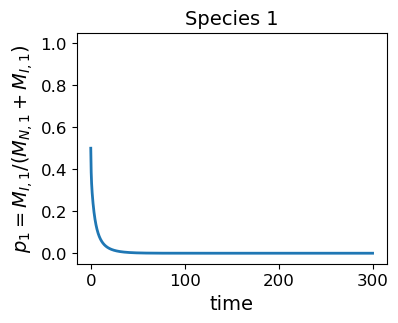

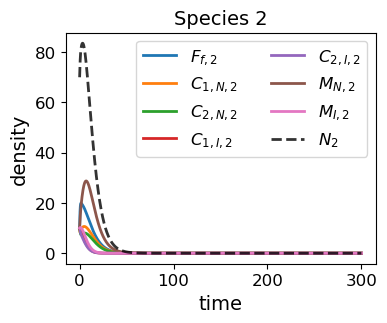

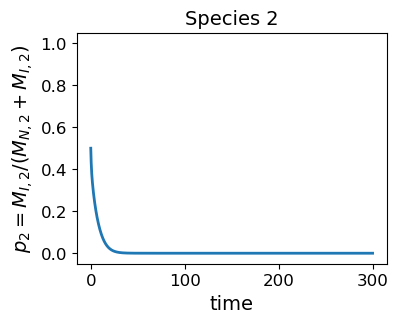

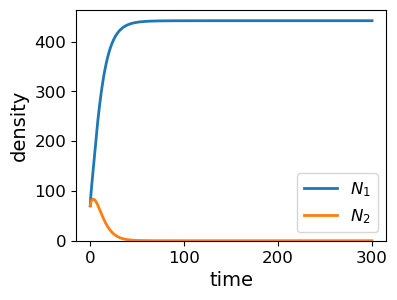

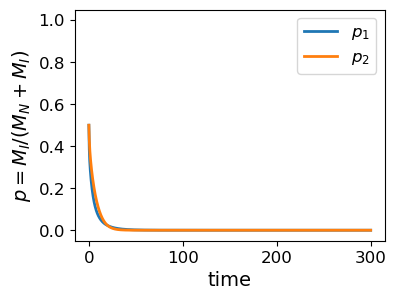

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq, root
from collections import Counter
from tqdm.auto import tqdm
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.patches import Patch

params = {
    'alpha1': 1.0,
    'beta1': 1.0,
    'gamma1': 0.01,
    'd1': 0.001,
    'b_N1': 2.0,
    's1': 0.8,

    'alpha2': 1.0,
    'beta2': 1.0,
    'gamma2': 0.01,
    'd2': 0.001,
    'b_N2': 1.0,
    's2': 0.8,

    'rho12': 0.9,
    'rho21': 0.9,
}


def male_type_frequencies(M_N, M_I, tol=0.0):
    male_total = M_N + M_I
    if male_total <= tol:
        return 0.0, 0.0
    return M_N / male_total, M_I / male_total


def two_species_ecoevo_rhs(time, y, params):
    (
        F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1,
        F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2,
    ) = y

    N1 = F_f1 + C1_N1 + C2_N1 + C1_I1 + C2_I1 + M_N1 + M_I1
    N2 = F_f2 + C1_N2 + C2_N2 + C1_I2 + C2_I2 + M_N2 + M_I2

    alpha1 = params['alpha1']
    beta1 = params['beta1']
    gamma1 = params['gamma1']
    d1 = params['d1']
    b_N1 = params['b_N1']
    s1 = params['s1']
    b_I1 = (1.0 - s1) * b_N1

    alpha2 = params['alpha2']
    beta2 = params['beta2']
    gamma2 = params['gamma2']
    d2 = params['d2']
    b_N2 = params['b_N2']
    s2 = params['s2']
    b_I2 = (1.0 - s2) * b_N2

    rho12 = params['rho12']
    rho21 = params['rho21']

    comp1 = d1 * (N1 + rho12 * N2)
    comp2 = d2 * (N2 + rho21 * N1)

    q_N1, q_I1 = male_type_frequencies(M_N1, M_I1)
    q_N2, q_I2 = male_type_frequencies(M_N2, M_I2)
    mating_N1 = alpha1 * q_N1 * F_f1
    mating_I1 = alpha1 * q_I1 * F_f1
    mating_N2 = alpha2 * q_N2 * F_f2
    mating_I2 = alpha2 * q_I2 * F_f2

    dF_f1 = -(mating_N1 + mating_I1) + (1.0 + b_N1) * beta1 * C2_N1 + (1.0 + b_I1) * beta1 * C2_I1 - comp1 * F_f1
    dC1_N1 = mating_N1 - (beta1 + comp1 + gamma1 * M_I1) * C1_N1
    dC2_N1 = beta1 * C1_N1 - (beta1 + comp1 + gamma1 * M_I1) * C2_N1
    dC1_I1 = mating_I1 + gamma1 * M_I1 * (C1_N1 + C2_N1 + C2_I1) - (beta1 + comp1) * C1_I1
    dC2_I1 = beta1 * C1_I1 - (beta1 + comp1 + gamma1 * M_I1) * C2_I1
    dM_N1 = b_N1 * beta1 * C2_N1 - comp1 * M_N1
    dM_I1 = b_I1 * beta1 * C2_I1 - comp1 * M_I1

    dF_f2 = -(mating_N2 + mating_I2) + (1.0 + b_N2) * beta2 * C2_N2 + (1.0 + b_I2) * beta2 * C2_I2 - comp2 * F_f2
    dC1_N2 = mating_N2 - (beta2 + comp2 + gamma2 * M_I2) * C1_N2
    dC2_N2 = beta2 * C1_N2 - (beta2 + comp2 + gamma2 * M_I2) * C2_N2
    dC1_I2 = mating_I2 + gamma2 * M_I2 * (C1_N2 + C2_N2 + C2_I2) - (beta2 + comp2) * C1_I2
    dC2_I2 = beta2 * C1_I2 - (beta2 + comp2 + gamma2 * M_I2) * C2_I2
    dM_N2 = b_N2 * beta2 * C2_N2 - comp2 * M_N2
    dM_I2 = b_I2 * beta2 * C2_I2 - comp2 * M_I2

    return np.array([
        dF_f1, dC1_N1, dC2_N1, dC1_I1, dC2_I1, dM_N1, dM_I1,
        dF_f2, dC1_N2, dC2_N2, dC1_I2, dC2_I2, dM_N2, dM_I2,
    ], dtype=float)

y0 = np.array([
    #10.0,0.0,0.0,0.0,0.0,10.0,0.0,
    10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0,
    10.0, 10.0, 10.0, 10.0, 10.0, 10.0, 10.0,
    #10.0, 10.0, 10.0, 0.0, 0.0, 10.0, 0.0,
], dtype=float)

t_span = (0.0, 300.0)
t_eval = np.linspace(t_span[0], t_span[1], 2000)

sol = solve_ivp(
    lambda time, y: two_species_ecoevo_rhs(time, y, params),
    t_span,
    y0,
    t_eval=t_eval,
    rtol=1e-8,
    atol=1e-10,
)

if not sol.success:
    raise RuntimeError(sol.message)

(
    F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1,
    F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2,
) = sol.y

N1 = F_f1 + C1_N1 + C2_N1 + C1_I1 + C2_I1 + M_N1 + M_I1
N2 = F_f2 + C1_N2 + C2_N2 + C1_I2 + C2_I2 + M_N2 + M_I2
p1 = np.divide(M_I1, M_N1 + M_I1, out=np.full_like(M_I1, np.nan), where=(M_N1 + M_I1) > 0.0)
p2 = np.divide(M_I2, M_N2 + M_I2, out=np.full_like(M_I2, np.nan), where=(M_N2 + M_I2) > 0.0)

figure_size = (4, 3)
axis_tick_fontsize = 12
axis_label_fontsize = 14

def plot_species(time, species_idx, F_f, C1_N, C2_N, C1_I, C2_I, M_N, M_I, N, p):
    fig, ax = plt.subplots(figsize=figure_size)
    ax.plot(time, F_f, label=rf'$F_{{f,{species_idx}}}$', lw=2)
    ax.plot(time, C1_N, label=rf'$C_{{1,N,{species_idx}}}$', lw=2)
    ax.plot(time, C2_N, label=rf'$C_{{2,N,{species_idx}}}$', lw=2)
    ax.plot(time, C1_I, label=rf'$C_{{1,I,{species_idx}}}$', lw=2)
    ax.plot(time, C2_I, label=rf'$C_{{2,I,{species_idx}}}$', lw=2)
    ax.plot(time, M_N, label=rf'$M_{{N,{species_idx}}}$', lw=2)
    ax.plot(time, M_I, label=rf'$M_{{I,{species_idx}}}$', lw=2)
    ax.plot(time, N, label=rf'$N_{species_idx}$', lw=2, ls='--', color='black', alpha=0.8)
    ax.set_xlabel('time', fontsize=axis_label_fontsize)
    ax.set_ylabel('density', fontsize=axis_label_fontsize)
    ax.set_title(f'Species {species_idx}', fontsize=axis_label_fontsize)
    ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
    ax.legend(ncol=2, frameon=True, fontsize=axis_tick_fontsize)

    fig, ax = plt.subplots(figsize=figure_size)
    ax.plot(time, p, lw=2)
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel('time', fontsize=axis_label_fontsize)
    ax.set_ylabel(rf'$p_{species_idx} = M_{{I,{species_idx}}} / (M_{{N,{species_idx}}} + M_{{I,{species_idx}}})$', fontsize=axis_label_fontsize)
    ax.set_title(f'Species {species_idx}', fontsize=axis_label_fontsize)
    ax.tick_params(axis='both', labelsize=axis_tick_fontsize)

plot_species(sol.t, 1, F_f1, C1_N1, C2_N1, C1_I1, C2_I1, M_N1, M_I1, N1, p1)
plot_species(sol.t, 2, F_f2, C1_N2, C2_N2, C1_I2, C2_I2, M_N2, M_I2, N2, p2)

fig, ax = plt.subplots(figsize=figure_size)
ax.plot(sol.t, N1, label=r'$N_1$', lw=2)
ax.plot(sol.t, N2, label=r'$N_2$', lw=2)
ax.set_ylim(bottom=-0.05)
ax.set_xlabel('time', fontsize=axis_label_fontsize)
ax.set_ylabel('density', fontsize=axis_label_fontsize)
ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
ax.legend(frameon=True, fontsize=axis_tick_fontsize)

fig, ax = plt.subplots(figsize=figure_size)
ax.plot(sol.t, p1, label=r'$p_1$', lw=2)
ax.plot(sol.t, p2, label=r'$p_2$', lw=2)
ax.set_ylim(-0.05, 1.05)
ax.set_xlabel('time', fontsize=axis_label_fontsize)
ax.set_ylabel(r'$p = M_I / (M_N + M_I)$', fontsize=axis_label_fontsize)
ax.tick_params(axis='both', labelsize=axis_tick_fontsize)
ax.legend(frameon=True, fontsize=axis_tick_fontsize)

plt.show()


### Setup

In [15]:
"""Two-species eco-evolutionary equilibrium utilities.

The Jacobian implemented here is analytic: every entry is the explicit
derivative of the full 14-dimensional ODE used in
``analysis_full_ecoevo_2sp.ipynb``.
"""


def _species_state(y, offset):
    return np.asarray(y[offset : offset + 7], dtype=float)


def male_frequency_derivatives(M_N, M_I, tol=0.0):
    male_total = M_N + M_I
    if male_total <= tol:
        return 0.0, 0.0, 0.0, 0.0, 0.0, 0.0
    # Divide frequencies by the total to avoid underflow from total**2.
    q_N = M_N / male_total
    q_I = M_I / male_total
    dqN_dMN = q_I / male_total
    dqN_dMI = -q_N / male_total
    dqI_dMN = -q_I / male_total
    dqI_dMI = q_N / male_total
    return q_N, q_I, dqN_dMN, dqN_dMI, dqI_dMN, dqI_dMI


def _fill_species_jacobian(
    J,
    y,
    offset,
    other_offset,
    alpha,
    beta,
    gamma,
    d,
    b_N,
    s,
    rho,
):
    F, C1_N, C2_N, C1_I, C2_I, M_N, M_I = _species_state(y, offset)
    N_self = F + C1_N + C2_N + C1_I + C2_I + M_N + M_I
    N_other = float(np.sum(_species_state(y, other_offset)))
    comp = d * (N_self + rho * N_other)
    b_I = (1.0 - s) * b_N
    q_N, q_I, dqN_dMN, dqN_dMI, dqI_dMN, dqI_dMI = male_frequency_derivatives(M_N, M_I)

    local = slice(offset, offset + 7)
    other = slice(other_offset, other_offset + 7)
    row_values = np.array([F, C1_N, C2_N, C1_I, C2_I, M_N, M_I], dtype=float)
    J[offset : offset + 7, other] = -d * rho * row_values[:, None]

    J[offset + 0, local] = [
        -alpha * (q_N + q_I) - comp - d * F,
        -d * F,
        (1.0 + b_N) * beta - d * F,
        -d * F,
        (1.0 + b_I) * beta - d * F,
        -d * F,
        -d * F,
    ]
    J[offset + 1, local] = [
        alpha * q_N - d * C1_N,
        -beta - comp - gamma * M_I - d * C1_N,
        -d * C1_N,
        -d * C1_N,
        -d * C1_N,
        alpha * F * dqN_dMN - d * C1_N,
        alpha * F * dqN_dMI - (gamma + d) * C1_N,
    ]
    J[offset + 2, local] = [
        -d * C2_N,
        beta - d * C2_N,
        -beta - comp - gamma * M_I - d * C2_N,
        -d * C2_N,
        -d * C2_N,
        -d * C2_N,
        -(gamma + d) * C2_N,
    ]
    J[offset + 3, local] = [
        alpha * q_I - d * C1_I,
        gamma * M_I - d * C1_I,
        gamma * M_I - d * C1_I,
        -beta - comp - d * C1_I,
        gamma * M_I - d * C1_I,
        alpha * F * dqI_dMN - d * C1_I,
        alpha * F * dqI_dMI + gamma * (C1_N + C2_N + C2_I) - d * C1_I,
    ]
    J[offset + 4, local] = [
        -d * C2_I,
        -d * C2_I,
        -d * C2_I,
        beta - d * C2_I,
        -beta - comp - gamma * M_I - d * C2_I,
        -d * C2_I,
        -(gamma + d) * C2_I,
    ]
    J[offset + 5, local] = [
        -d * M_N,
        -d * M_N,
        b_N * beta - d * M_N,
        -d * M_N,
        -d * M_N,
        -comp - d * M_N,
        -d * M_N,
    ]
    J[offset + 6, local] = [
        -d * M_I,
        -d * M_I,
        -d * M_I,
        -d * M_I,
        b_I * beta - d * M_I,
        -d * M_I,
        -comp - d * M_I,
    ]

def two_species_analytic_jacobian(y, params):
    """Analytic Jacobian of the full 14-dimensional two-species ODE."""
    y = np.asarray(y, dtype=float)
    J = np.zeros((14, 14), dtype=float)
    _fill_species_jacobian(
        J,
        y,
        offset=0,
        other_offset=7,
        alpha=params["alpha1"],
        beta=params["beta1"],
        gamma=params["gamma1"],
        d=params["d1"],
        b_N=params["b_N1"],
        s=params["s1"],
        rho=params["rho12"],
    )
    _fill_species_jacobian(
        J,
        y,
        offset=7,
        other_offset=0,
        alpha=params["alpha2"],
        beta=params["beta2"],
        gamma=params["gamma2"],
        d=params["d2"],
        b_N=params["b_N2"],
        s=params["s2"],
        rho=params["rho21"],
    )
    return J


def two_species_equilibrium_residual(y, params, rhs_func):
    return rhs_func(0.0, np.asarray(y, dtype=float), params)


def classify_stability_margin(stability_margin, eigen_tol=1e-8):
    if stability_margin < -eigen_tol:
        return "stable"
    if stability_margin > eigen_tol:
        return "unstable"
    return "neutral"


def _species_family(y_species, tol=1e-8):
    F, C1_N, C2_N, C1_I, C2_I, M_N, M_I = np.asarray(y_species, dtype=float)
    N = float(F + C1_N + C2_N + C1_I + C2_I + M_N + M_I)
    if N <= tol:
        return "extinct"
    if M_I <= tol and M_N > tol:
        return "p0"
    if M_N <= tol and M_I > tol:
        return "p1"
    if M_N + M_I <= tol:
        return "no_males"
    return "interior"


def equilibrium_family_2sp(y, tol=1e-8):
    y = np.asarray(y, dtype=float)
    return f"sp1:{_species_family(y[:7], tol)}|sp2:{_species_family(y[7:], tol)}"


def two_species_equilibrium_metrics(y):
    y = np.asarray(y, dtype=float)
    y1 = y[:7]
    y2 = y[7:]
    N1 = float(np.sum(y1))
    N2 = float(np.sum(y2))
    male1 = y1[5] + y1[6]
    male2 = y2[5] + y2[6]
    p1 = float(y1[6] / male1) if male1 > 1e-12 else np.nan
    p2 = float(y2[6] / male2) if male2 > 1e-12 else np.nan
    return {"N1": N1, "N2": N2, "p1": p1, "p2": p2}


def equilibrium_distance_2sp(y1, y2):
    y1 = np.asarray(y1, dtype=float)
    y2 = np.asarray(y2, dtype=float)
    scale = max(1.0, np.linalg.norm(y1, ord=np.inf), np.linalg.norm(y2, ord=np.inf))
    return float(np.linalg.norm(y1 - y2, ord=np.inf) / scale)


def rare_species_intrinsic_growth(params, species_idx):
    """Maximal rare-species growth before external competition mortality.

    At vanishing density, gamma*M_I resets are second order. The male
    strategy with the larger fecundity determines asymptotic invasion.
    This assumes nonnegative gamma and 0 <= s <= 1.
    """
    alpha = params[f"alpha{species_idx}"]
    beta = params[f"beta{species_idx}"]
    b_N = params[f"b_N{species_idx}"]
    s = params[f"s{species_idx}"]
    if min(alpha, beta, b_N) <= 0 or not 0 <= s <= 1:
        raise ValueError("Invasion test requires positive alpha, beta, b_N and 0 <= s <= 1.")
    b = max(b_N, (1 - s) * b_N)
    if alpha == beta:
        return alpha * np.expm1(np.log1p(b) / 3.0)
    def equation(g):
        return (alpha + g) * (beta + g)**2 - alpha * (1 + b) * beta**2
    upper = max(alpha, beta)
    while equation(upper) <= 0:
        upper *= 2
    return brentq(equation, 0.0, upper, xtol=1e-14)


def full_equilibrium_stability(y, params, eigen_tol=1e-8, extinction_tol=1e-5, jacobian=None):
    """Use resident eigenvalues plus invasion rates at extinction boundaries.

    The mating-frequency RHS is not differentiable at an absent species;
    its zero-frequency Jacobian must never be used for invasion stability.
    Species below the density cutoff are treated as extinct for this test.
    """
    y = np.asarray(y, dtype=float)
    densities = [float(y[:7].sum()), float(y[7:].sum())]
    present = [density > extinction_tol for density in densities]
    J = two_species_analytic_jacobian(y, params) if jacobian is None else jacobian
    if all(present):
        eig = np.linalg.eigvals(J)
        invasion = {}
        method = "full analytic Jacobian"
    else:
        active = [k for i in range(2) if present[i] for k in range(7*i, 7*i+7)]
        resident_eig = np.linalg.eigvals(J[np.ix_(active, active)]) if active else np.array([], dtype=complex)
        invasion = {}
        for i in range(2):
            if not present[i]:
                species_idx = i + 1
                rho = params["rho12" if i == 0 else "rho21"]
                external_mortality = params[f"d{species_idx}"] * rho * densities[1-i]
                invasion[f"species{species_idx}"] = rare_species_intrinsic_growth(params, species_idx) - external_mortality
        eig = np.r_[resident_eig, list(invasion.values())]
        method = "resident analytic Jacobian and rare-species invasion"
    margin = float(np.max(eig.real))
    return {
        "eigvals": eig, "stability_margin": margin,
        "stability_class": classify_stability_margin(margin, eigen_tol),
        "invasion_margins": invasion, "stability_method": method,
    }


def refine_two_species_equilibrium(
    seed,
    params,
    rhs_func,
    root_tol=1e-11,
    residual_tol=1e-7,
    eigen_tol=1e-8,
):
    seed = np.maximum(np.asarray(seed, dtype=float), 0.0)
    sol = root(
        lambda y: two_species_equilibrium_residual(y, params, rhs_func),
        seed,
        jac=lambda y: two_species_analytic_jacobian(y, params),
        method="hybr",
        tol=root_tol,
    )
    y_star = np.asarray(sol.x, dtype=float)
    if not np.all(np.isfinite(y_star)) or np.min(y_star) < -1e-7:
        return None
    y_star = np.maximum(y_star, 0.0)
    y_star[np.abs(y_star) < 1e-11] = 0.0

    residual = two_species_equilibrium_residual(y_star, params, rhs_func)
    residual_norm = float(np.linalg.norm(residual, ord=np.inf))
    if not np.isfinite(residual_norm) or residual_norm > residual_tol:
        return None

    J = two_species_analytic_jacobian(y_star, params)
    if not np.all(np.isfinite(J)):
        return None
    metrics = two_species_equilibrium_metrics(y_star)
    return {
        "y_star": y_star,
        "residual_norm": residual_norm,
        "jacobian": J,
        **full_equilibrium_stability(y_star, params, eigen_tol=eigen_tol, jacobian=J),
        "family": equilibrium_family_2sp(y_star, tol=1e-5),
        **metrics,
    }


def _single_species_seed(density_scale, p_guess):
    if density_scale <= 0.0:
        return np.zeros(7, dtype=float)
    n_part = 1.0 - p_guess
    i_part = p_guess
    return np.array(
        [
            10.0 * density_scale,
            1.0 * density_scale * n_part,
            1.0 * density_scale * n_part,
            1.0 * density_scale * i_part,
            1.0 * density_scale * i_part,
            5.0 * density_scale * n_part,
            5.0 * density_scale * i_part,
        ],
        dtype=float,
    )




### Full-model scan of the $(s,\rho)$ plane

Scan $s=s_1=s_2$ and $\rho=\rho_{12}=\rho_{21}$ to compute and retain equilibria of the 14-dimensional full eco-evolutionary model, including the infanticidal strategy. The results are used to visualize differences from the reduced no-infanticide model.


In [16]:
# ============================================================
# Minimal 2D phase diagrams on the (s, rho) plane
#
# Current classification:
#   Ecology:
#       stable two-species internal equilibrium exists, or otherwise
#       which single-species boundary equilibrium is stable.
#   Evolution:
#       p value at the selected stable equilibrium, classified as
#       0, 1, or polymorphic for the extant species.
# ============================================================


required_names = [
    "params",
    "two_species_ecoevo_rhs",
    "two_species_analytic_jacobian",
    "refine_two_species_equilibrium",
    "equilibrium_distance_2sp",
    "_single_species_seed",
]
missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(
        "Run the two-species equilibrium utility cell first. Missing names: "
        + ", ".join(missing)
    )


# ------------------------------------------------------------
# Parameter setter
# ------------------------------------------------------------

def params_with_common_s_rho(base_params, s_value, rho_value):
    p = dict(base_params)
    p["s1"] = float(s_value)
    p["s2"] = float(s_value)
    p["rho12"] = float(rho_value)
    p["rho21"] = float(rho_value)
    return p


# ------------------------------------------------------------
# Utility functions
# ------------------------------------------------------------

def _seed_from_equilibrium(eq_or_seed):
    if isinstance(eq_or_seed, dict) and "y_star" in eq_or_seed:
        return np.asarray(eq_or_seed["y_star"], dtype=float)
    return np.asarray(eq_or_seed, dtype=float)


def parse_family(family):
    """
    Example:
        'sp1:p0|sp2:interior' -> ('p0', 'interior')
    """
    fam1 = family.split("|")[0].split(":")[1]
    fam2 = family.split("|")[1].split(":")[1]
    return fam1, fam2


def ecological_label_from_family(family):
    fam1, fam2 = parse_family(family)

    if fam1 == "extinct" and fam2 == "extinct":
        return "both_extinct"
    if fam1 == "extinct":
        return "species2_only"
    if fam2 == "extinct":
        return "species1_only"
    return "coexistence"


def is_coexistence(eq):
    return ecological_label_from_family(eq["family"]) == "coexistence"


def is_stable_full(eq):
    return eq["stability_class"] == "stable"


# ------------------------------------------------------------
# Seed bank and equilibrium search
# ------------------------------------------------------------

def two_species_phase_seed_bank(
    previous_equilibria=None,
    upper_equilibria=None,
    extra_seeds=None,
):
    seeds = []

    for group in (previous_equilibria, upper_equilibria):
        if group is not None:
            seeds.extend(_seed_from_equilibrium(item) for item in group)

    if extra_seeds is not None:
        seeds.extend(np.asarray(seed, dtype=float) for seed in extra_seeds)

    # Extinction
    seeds.append(np.zeros(14, dtype=float))

    # A wider seed bank is useful because the system can be multistable.
    for density in (0.1, 1.0, 10.0, 40.0):
        # Single-species boundary seeds
        seeds.append(np.r_[_single_species_seed(density, 0.0), np.zeros(7)])
        seeds.append(np.r_[_single_species_seed(density, 1.0), np.zeros(7)])
        seeds.append(np.r_[np.zeros(7), _single_species_seed(density, 0.0)])
        seeds.append(np.r_[np.zeros(7), _single_species_seed(density, 1.0)])

        # Two-species seeds
        for p1_guess, p2_guess in (
            (0.0, 0.0),
            (1.0, 1.0),
            (0.5, 0.5),
            (1.0, 0.0),
            (0.0, 1.0),
            (0.2, 0.8),
            (0.8, 0.2),
        ):
            seeds.append(
                np.r_[
                    _single_species_seed(density, p1_guess),
                    _single_species_seed(density, p2_guess),
                ]
            )

    return seeds


def find_two_species_equilibria_phase(
    params,
    rhs_func,
    previous_equilibria=None,
    upper_equilibria=None,
    extra_seeds=None,
    dedupe_tol=1e-6,
):
    equilibria = []

    for seed in two_species_phase_seed_bank(
        previous_equilibria=previous_equilibria,
        upper_equilibria=upper_equilibria,
        extra_seeds=extra_seeds,
    ):
        result = refine_two_species_equilibrium(seed, params, rhs_func)
        if result is None:
            continue

        duplicate = False
        for existing in equilibria:
            if equilibrium_distance_2sp(result["y_star"], existing["y_star"]) < dedupe_tol:
                duplicate = True
                break

        if not duplicate:
            equilibria.append(result)


    family_order = {
        "extinct": 0,
        "p0": 1,
        "interior": 2,
        "p1": 3,
        "no_males": 4,
    }

    def sort_key(item):
        fam1, fam2 = parse_family(item["family"])
        return (
            item["stability_class"] != "stable",
            family_order.get(fam1, 99),
            family_order.get(fam2, 99),
            item["N1"] + item["N2"],
            np.nan_to_num(item["p1"], nan=-1.0),
            np.nan_to_num(item["p2"], nan=-1.0),
        )

    equilibria.sort(key=sort_key)
    return equilibria


# ------------------------------------------------------------
# Simple ecology/evolution classification used by final figures
# ------------------------------------------------------------

ecology_label_order = [
    "coexistence",
    "species1_only",
    "species2_only",
    "alternative_exclusion",
    "no_stable_state_found",
]


def _strategy_state_label(p, tol=1e-6):
    if not np.isfinite(p):
        return "extinct"
    if p <= tol:
        return "0"
    if p >= 1.0 - tol:
        return "1"
    return "polymorphic"


def _evolution_label_from_equilibrium(eq):
    return (
        f"sp1:{_strategy_state_label(eq['p1'])}"
        f" | sp2:{_strategy_state_label(eq['p2'])}"
    )


def _best_equilibrium(candidates):
    if not candidates:
        return None
    return min(
        candidates,
        key=lambda eq: (
            np.nan_to_num(eq.get("stability_margin", np.inf), nan=np.inf),
            -(eq.get("N1", 0.0) + eq.get("N2", 0.0)),
        ),
    )


def summarize_simple_ecology_evolution(equilibria):
    stable_full = [eq for eq in equilibria if is_stable_full(eq)]

    stable_coexistence = [eq for eq in stable_full if is_coexistence(eq)]
    stable_species1_only = [
        eq for eq in stable_full
        if ecological_label_from_family(eq["family"]) == "species1_only"
    ]
    stable_species2_only = [
        eq for eq in stable_full
        if ecological_label_from_family(eq["family"]) == "species2_only"
    ]

    has_stable_coexistence = len(stable_coexistence) > 0
    has_stable_species1_only = len(stable_species1_only) > 0
    has_stable_species2_only = len(stable_species2_only) > 0

    if has_stable_coexistence:
        ecology_label = "coexistence"
        selected = _best_equilibrium(stable_coexistence)
    elif has_stable_species1_only and has_stable_species2_only:
        ecology_label = "alternative_exclusion"
        selected = _best_equilibrium(stable_species1_only + stable_species2_only)
    elif has_stable_species1_only:
        ecology_label = "species1_only"
        selected = _best_equilibrium(stable_species1_only)
    elif has_stable_species2_only:
        ecology_label = "species2_only"
        selected = _best_equilibrium(stable_species2_only)
    else:
        ecology_label = "no_stable_state_found"
        selected = _best_equilibrium(stable_full)

    if ecology_label == "coexistence" and selected is not None:
        evolution_label = _evolution_label_from_equilibrium(selected)
    else:
        evolution_label = "non_coexistence"

    return {
        "ecology_label": ecology_label,
        "evolution_label": evolution_label,
        "selected_equilibrium": selected,
        "has_stable_coexistence": has_stable_coexistence,
        "has_stable_species1_only": has_stable_species1_only,
        "has_stable_species2_only": has_stable_species2_only,
    }


# ------------------------------------------------------------
# Run scan and keep equilibrium results in memory
# ------------------------------------------------------------


# Common full/reduced scan grid. Reduce SCAN_GRID_SIZE for a quick check.
SCAN_GRID_SIZE = 101
s_values_2d = np.linspace(0.0, 1.0, SCAN_GRID_SIZE)
rho_values_2d = np.linspace(0.0, 1.0, SCAN_GRID_SIZE)

ecology_labels_2d = np.empty((len(s_values_2d), len(rho_values_2d)), dtype=object)
evolution_labels_2d = np.empty((len(s_values_2d), len(rho_values_2d)), dtype=object)
selected_equilibria_2d = [[None for _ in rho_values_2d] for _ in s_values_2d]

stable_coexistence_2d = np.zeros((len(s_values_2d), len(rho_values_2d)), dtype=bool)
stable_species1_only_2d = np.zeros((len(s_values_2d), len(rho_values_2d)), dtype=bool)
stable_species2_only_2d = np.zeros((len(s_values_2d), len(rho_values_2d)), dtype=bool)

equilibria_grid_2d = [
    [None for _ in rho_values_2d]
    for _ in s_values_2d
]

base_phase_seeds = []

if "y0" in globals():
    base_phase_seeds.append(np.asarray(y0, dtype=float))

if "sol" in globals():
    base_phase_seeds.append(np.asarray(sol.y[:, -1], dtype=float))


phase_scan_progress = tqdm(
    total=len(s_values_2d) * len(rho_values_2d),
    desc="Scanning (s, rho)",
    unit="point",
)

for i, s_value in enumerate(s_values_2d):
    phase_scan_progress.set_description(
        f"Scanning row {i + 1}/{len(s_values_2d)}"
    )

    if i % 2 == 0:
        rho_indices = range(len(rho_values_2d))
    else:
        rho_indices = range(len(rho_values_2d) - 1, -1, -1)

    horizontal_equilibria = None

    for j in rho_indices:
        rho_value = rho_values_2d[j]
        phase_scan_progress.set_postfix(
            s=f"{s_value:.4f}",
            rho=f"{rho_value:.4f}",
        )
        upper_equilibria = equilibria_grid_2d[i - 1][j] if i > 0 else None

        params_tr = params_with_common_s_rho(
            params,
            s_value=s_value,
            rho_value=rho_value,
        )

        equilibria = find_two_species_equilibria_phase(
            params_tr,
            two_species_ecoevo_rhs,
            previous_equilibria=horizontal_equilibria,
            upper_equilibria=upper_equilibria,
            extra_seeds=base_phase_seeds,
        )

        equilibria_grid_2d[i][j] = equilibria
        horizontal_equilibria = equilibria

        summary = summarize_simple_ecology_evolution(equilibria)

        ecology_labels_2d[i, j] = summary["ecology_label"]
        evolution_labels_2d[i, j] = summary["evolution_label"]
        selected_equilibria_2d[i][j] = summary["selected_equilibrium"]

        stable_coexistence_2d[i, j] = summary["has_stable_coexistence"]
        stable_species1_only_2d[i, j] = summary["has_stable_species1_only"]
        stable_species2_only_2d[i, j] = summary["has_stable_species2_only"]

        phase_scan_progress.update(1)

phase_scan_progress.close()

ecology_counts_2d = Counter(ecology_labels_2d.ravel())
evolution_counts_2d = Counter(evolution_labels_2d.ravel())

phase_diagram_2sp_s_rho_scan = {
    "s_values": s_values_2d,
    "rho_values": rho_values_2d,
    "ecology_labels": ecology_labels_2d,
    "ecology_counts": ecology_counts_2d,
    "evolution_labels": evolution_labels_2d,
    "evolution_counts": evolution_counts_2d,
    "stable_coexistence": stable_coexistence_2d,
    "stable_species1_only": stable_species1_only_2d,
    "stable_species2_only": stable_species2_only_2d,
    "selected_equilibria": selected_equilibria_2d,
    "equilibria_grid": equilibria_grid_2d,
    "params": dict(params),
    "stability_method": "resident analytic Jacobian and rare-species invasion at extinction boundaries",
}


print("ecological outcome counts:")
for label in ecology_label_order:
    if ecology_counts_2d.get(label, 0) > 0:
        print(f"  {label}: {ecology_counts_2d[label]}")

print("\nevolutionary outcome counts before coexistence masking:")
for label, count in sorted(evolution_counts_2d.items()):
    print(f"  {label}: {count}")


Scanning (s, rho):   0%|          | 0/10201 [00:00<?, ?point/s]

ecological outcome counts:
  coexistence: 8577
  species1_only: 1624

evolutionary outcome counts before coexistence masking:
  non_coexistence: 1624
  sp1:0 | sp2:0: 1746
  sp1:1 | sp2:0: 123
  sp1:1 | sp2:1: 2936
  sp1:1 | sp2:polymorphic: 2161
  sp1:polymorphic | sp2:0: 1394
  sp1:polymorphic | sp2:polymorphic: 217


### Reduced no-infanticide model scan of the $(s,\rho)$ plane

Evaluate the eight-dimensional reduced model without the infanticidal strategy on the same $(s,\rho)$ grid as the full model.


In [17]:
if "params" not in globals() or "two_species_analytic_jacobian" not in globals():
    raise RuntimeError("Run the parameter and analytic Jacobian cells first.")


def no_infanticide_capacity(params_reduced, species_idx):
    """Positive equilibrium mortality and single-species adult density."""
    alpha = params_reduced[f"alpha{species_idx}"]
    beta = params_reduced[f"beta{species_idx}"]
    d = params_reduced[f"d{species_idx}"]
    b = params_reduced[f"b_N{species_idx}"]
    if min(alpha, beta, d, b) <= 0:
        raise ValueError("alpha, beta, d and b_N must be positive.")
    if alpha == beta:
        c = alpha * np.expm1(np.log1p(b) / 3.0)
    else:
        def equation(c):
            return (alpha + c) * (beta + c)**2 - alpha * (1 + b) * beta**2
        upper = max(alpha, beta)
        while equation(upper) <= 0:
            upper *= 2
        c = brentq(equation, 0.0, upper, xtol=1e-14)
    return c, c / d


def no_infanticide_species_state(N, c, params_reduced, species_idx):
    alpha = params_reduced[f"alpha{species_idx}"]
    beta = params_reduced[f"beta{species_idx}"]
    b = params_reduced[f"b_N{species_idx}"]
    C1 = alpha / (beta + c)
    C2 = alpha * beta / (beta + c)**2
    M = b * beta * C2 / c
    weights = np.array([1.0, C1, C2, 0.0, 0.0, M, 0.0])
    return N * weights / weights.sum()


def analytic_reduced_coexistence(params_reduced, eigen_tol=1e-8):
    """Construct the positive coexistence equilibrium, then test ecology only.

    No multidimensional root search, clipping, or extinction cutoff is used.
    Singular competition matrices have no isolated asymptotically stable
    coexistence equilibrium, including the equal-capacity neutral continuum.
    """
    c1, K1 = no_infanticide_capacity(params_reduced, 1)
    c2, K2 = no_infanticide_capacity(params_reduced, 2)
    rho12 = params_reduced["rho12"]
    rho21 = params_reduced["rho21"]
    determinant = 1.0 - rho12 * rho21
    if abs(determinant) <= 1e-12:
        return None
    N1 = (K1 - rho12 * K2) / determinant
    N2 = (K2 - rho21 * K1) / determinant
    # Machine-roundoff guard at the exact zero-density boundary.
    positivity_tol = 64 * np.finfo(float).eps * max(1.0, K1, K2)
    if N1 <= positivity_tol or N2 <= positivity_tol:
        return None
    y_full = np.r_[
        no_infanticide_species_state(N1, c1, params_reduced, 1),
        no_infanticide_species_state(N2, c2, params_reduced, 2),
    ]
    active = [0, 1, 2, 5, 7, 8, 9, 12]
    jac = two_species_analytic_jacobian(y_full, params_reduced)[np.ix_(active, active)]
    eig = np.linalg.eigvals(jac)
    margin = float(np.max(eig.real))
    stability = "stable" if margin < -eigen_tol else "unstable" if margin > eigen_tol else "neutral"
    residual = two_species_ecoevo_rhs(0.0, y_full, params_reduced)
    residual_norm = float(np.linalg.norm(residual, ord=np.inf))
    if not np.all(np.isfinite(y_full)) or residual_norm > 1e-9 * max(1.0, N1, N2):
        raise RuntimeError("Analytic reduced equilibrium failed its ODE residual check.")
    return {
        "y_star": y_full[active], "N1": N1, "N2": N2,
        "coexistence": True, "species1_only": False,
        "species2_only": False, "extinct": False,
        "residual_norm": residual_norm, "jacobian": jac,
        "eigenvalues": eig, "stability_margin": margin,
        "stability_class": stability,
    }


s_values_reduced_rho = s_values_2d.copy()
rho_values_reduced = rho_values_2d.copy()
coexistence_reduced_s_rho = np.zeros((len(s_values_reduced_rho), len(rho_values_reduced)), dtype=bool)
equilibria_by_rho_reduced = []

for j, rho_value in enumerate(rho_values_reduced):
    params_reduced = dict(params, rho12=float(rho_value), rho21=float(rho_value))
    eq = analytic_reduced_coexistence(params_reduced)
    equilibria_by_rho_reduced.append([] if eq is None else [eq])
    coexistence_reduced_s_rho[:, j] = eq is not None and eq["stability_class"] == "stable"

phase_diagram_2sp_s_rho_no_infanticide_reduced_result = {
    "s_values": s_values_reduced_rho,
    "rho_values": rho_values_reduced,
    "coexistence": coexistence_reduced_s_rho,
    # Only positive coexistence candidates are stored; boundary equilibria
    # are not needed for this baseline coexistence mask.
    "equilibria_by_rho": equilibria_by_rho_reduced,
    "params": dict(params),
    "method": "analytic positive coexistence and ecological Jacobian",
}

print(f"stable no-infanticide coexistence grid points: {coexistence_reduced_s_rho.sum()}")
print("s is absent from the reduced system; all rows are identical.")


stable no-infanticide coexistence grid points: 5959
s is absent from the reduced system; all rows are identical.


### Publication figures: difference map and evolutionary outcomes within coexistence regions

Use the full-model and reduced no-infanticide model results held in memory to display the phase-plane diagrams.


revised figure summary on the (s, rho) grid:
  coexistence without infanticide: 5959
  coexistence gained by infanticide evolution: 2618
  no stable coexistence with infanticide: 1624
  evolutionary outcomes across coexistence and exclusion regions:
    species 2 excluded: $p_1^*=0$: 1176
    species 2 excluded: $0<p_1^*<1$: 117
    species 2 excluded: $p_1^*=1$: 331
    $p_1^*=0,\ p_2^*=0$: 1746
    $p_1^*=1,\ p_2^*=0$: 123
    $p_1^*=1,\ p_2^*=1$: 2936
    $p_1^*=1,\ 0<p_2^*<1$: 2161
    $0<p_1^*<1,\ p_2^*=0$: 1394
    $0<p_1^*<1,\ 0<p_2^*<1$: 217


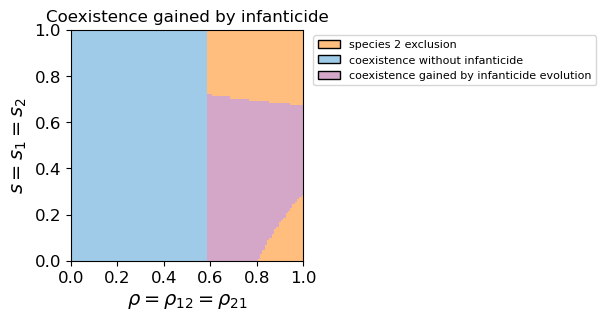

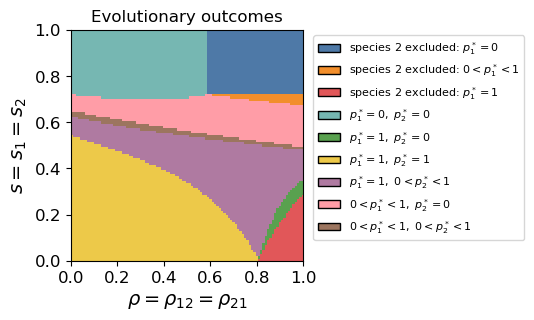

In [18]:
full_scan = phase_diagram_2sp_s_rho_scan
reduced_scan = phase_diagram_2sp_s_rho_no_infanticide_reduced_result

s_values = np.asarray(full_scan["s_values"], dtype=float)
rho_values = np.asarray(full_scan["rho_values"], dtype=float)
full_ecology_labels = np.asarray(full_scan["ecology_labels"], dtype=object)
full_evolution_labels = np.asarray(full_scan["evolution_labels"], dtype=object)

reduced_s_values = np.asarray(reduced_scan["s_values"], dtype=float)
reduced_rho_values = np.asarray(reduced_scan["rho_values"], dtype=float)
reduced_coexistence = np.asarray(reduced_scan["coexistence"], dtype=bool)

if full_ecology_labels.shape != reduced_coexistence.shape:
    raise ValueError(
        "Full and reduced scan grids have different shapes: "
        f"{full_ecology_labels.shape} vs {reduced_coexistence.shape}"
    )

if not np.allclose(s_values, reduced_s_values) or not np.allclose(rho_values, reduced_rho_values):
    raise ValueError("Full and reduced scan grids use different s or rho values.")

full_coexistence = full_ecology_labels == "coexistence"
reduced_no_coexistence = ~reduced_coexistence
noninfanticide_coexistence_label = "sp1:0 | sp2:0"

# Coexistence in the full model where at least one species has p_i > 0.
infanticide_enabled_coexistence = (
    full_coexistence
    & (full_evolution_labels != noninfanticide_coexistence_label)
)

# The focal gain: no stable coexistence without infanticide, but stable
# coexistence appears in the full eco-evolutionary model with infanticide.
gained_coexistence = infanticide_enabled_coexistence & reduced_no_coexistence

# Keep the original three classes and colors for the current parameter set.
# Add distinct classes only when other outcomes actually occur.
already_coexistence = reduced_coexistence & full_coexistence
difference_code = np.full(full_ecology_labels.shape, -1, dtype=int)
difference_code[full_ecology_labels == "species1_only"] = 0
difference_code[already_coexistence] = 1
difference_code[gained_coexistence] = 2
difference_labels = [
    "species 2 exclusion",
    "coexistence without infanticide",
    "coexistence gained by infanticide evolution",
]
difference_colors = ["#ffbe7d", "#a0cbe8", "#d4a6c8"]
extra_difference_classes = [
    (full_ecology_labels == "species2_only", "species 1 exclusion", "#8cd17d"),
    (full_ecology_labels == "alternative_exclusion", "alternative exclusion", "#b6992d"),
    (full_ecology_labels == "no_stable_state_found", "no stable equilibrium found", "#bab0ac"),
    (full_coexistence, "other stable coexistence", "#76b7b2"),
]
for mask, label, color in extra_difference_classes:
    mask = mask & (difference_code == -1)
    if np.any(mask):
        difference_code[mask] = len(difference_labels)
        difference_labels.append(label)
        difference_colors.append(color)
if np.any(difference_code == -1):
    raise ValueError("Unclassified ecological outcome in the difference map.")
difference_cmap = ListedColormap(difference_colors)
difference_norm = BoundaryNorm(
    np.arange(-0.5, len(difference_labels) + 0.5, 1.0), difference_cmap.N
)

rho_min, rho_max = rho_values[0], rho_values[-1]
s_min, s_max = s_values[0], s_values[-1]
axis_ticks = np.arange(0.0, 1.01, 0.2)

fig_difference, ax_difference = plt.subplots(figsize=(3.0, 3.0))
ax_difference.imshow(
    difference_code,
    origin="lower",
    aspect="auto",
    interpolation="none",
    cmap=difference_cmap,
    norm=difference_norm,
    extent=[rho_min, rho_max, s_min, s_max],
)

ax_difference.set_xticks(axis_ticks)
ax_difference.set_yticks(axis_ticks)
ax_difference.set_xlabel(r"$\rho=\rho_{12}=\rho_{21}$", fontsize=axis_label_fontsize)
ax_difference.set_ylabel(r"$s=s_1=s_2$", fontsize=axis_label_fontsize)
ax_difference.tick_params(axis="both", labelsize=axis_tick_fontsize)
ax_difference.set_title("Coexistence gained by infanticide")

difference_legend_handles = [
    Patch(facecolor=color, edgecolor="black", label=label)
    for color, label in zip(difference_colors, difference_labels)
]
ax_difference.legend(
    handles=difference_legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    frameon=True,
    fontsize=8,
)


outside_label = "outside_stable_coexistence"
coexistence_evolution_labels = np.full(
    full_evolution_labels.shape,
    outside_label,
    dtype=object,
)
coexistence_evolution_labels[full_coexistence] = full_evolution_labels[full_coexistence]

# Classify the surviving species in competitive-exclusion regions.
selected_equilibria = full_scan["selected_equilibria"]
for i, j in np.argwhere(full_ecology_labels == "species1_only"):
    eq = selected_equilibria[i][j]
    if eq is None or not np.isfinite(eq["p1"]):
        raise ValueError(f"Missing surviving-species p1 at grid point {(i, j)}")
    p1 = eq["p1"]
    state = _strategy_state_label(p1)
    coexistence_evolution_labels[i, j] = f"species2_excluded | sp1:{state}"

evolution_label_order = [
    outside_label,
    "species2_excluded | sp1:0",
    "species2_excluded | sp1:polymorphic",
    "species2_excluded | sp1:1",
    "sp1:0 | sp2:0",
    "sp1:0 | sp2:1",
    "sp1:0 | sp2:polymorphic",
    "sp1:1 | sp2:0",
    "sp1:1 | sp2:1",
    "sp1:1 | sp2:polymorphic",
    "sp1:polymorphic | sp2:0",
    "sp1:polymorphic | sp2:1",
    "sp1:polymorphic | sp2:polymorphic",
]

# Tableau 10 qualitative palette; no hatch overlays.
evolution_color_by_label = {
    outside_label: "#ffffff",
    "species2_excluded | sp1:0": "#4e79a7",
    "species2_excluded | sp1:polymorphic": "#f28e2b",
    "species2_excluded | sp1:1": "#e15759",
    "sp1:0 | sp2:0": "#76b7b2",
    "sp1:0 | sp2:1": "#4e79a7",
    "sp1:0 | sp2:polymorphic": "#f28e2b",
    "sp1:1 | sp2:0": "#59a14f",
    "sp1:1 | sp2:1": "#edc949",
    "sp1:1 | sp2:polymorphic": "#af7aa1",
    "sp1:polymorphic | sp2:0": "#ff9da7",
    "sp1:polymorphic | sp2:1": "#e15759",
    "sp1:polymorphic | sp2:polymorphic": "#9c755f",
}

evolution_display_label = {
    outside_label: "other non-coexistence outcome",
    "species2_excluded | sp1:0": r"species 2 excluded: $p_1^*=0$",
    "species2_excluded | sp1:polymorphic": r"species 2 excluded: $0<p_1^*<1$",
    "species2_excluded | sp1:1": r"species 2 excluded: $p_1^*=1$",
    "sp1:0 | sp2:0": r"$p_1^*=0,\ p_2^*=0$",
    "sp1:0 | sp2:1": r"$p_1^*=0,\ p_2^*=1$",
    "sp1:0 | sp2:polymorphic": r"$p_1^*=0,\ 0<p_2^*<1$",
    "sp1:1 | sp2:0": r"$p_1^*=1,\ p_2^*=0$",
    "sp1:1 | sp2:1": r"$p_1^*=1,\ p_2^*=1$",
    "sp1:1 | sp2:polymorphic": r"$p_1^*=1,\ 0<p_2^*<1$",
    "sp1:polymorphic | sp2:0": r"$0<p_1^*<1,\ p_2^*=0$",
    "sp1:polymorphic | sp2:1": r"$0<p_1^*<1,\ p_2^*=1$",
    "sp1:polymorphic | sp2:polymorphic": r"$0<p_1^*<1,\ 0<p_2^*<1$",
}

evolution_labels_present = [
    label for label in evolution_label_order
    if np.any(coexistence_evolution_labels == label)
]
evolution_labels_present.extend(
    label for label in sorted(set(coexistence_evolution_labels.ravel()))
    if label not in evolution_labels_present
)

tableau_colors = [
    "#4e79a7", "#f28e2b", "#e15759", "#76b7b2", "#59a14f",
    "#edc949", "#af7aa1", "#ff9da7", "#9c755f",
]
colored_labels = [label for label in evolution_labels_present if label != outside_label]
if len(colored_labels) > len(tableau_colors):
    raise ValueError("More than nine outcomes require an expanded non-gray palette.")
used_colors = set()
for label in colored_labels:
    color = evolution_color_by_label[label]
    if color in used_colors:
        color = next(c for c in tableau_colors if c not in used_colors)
    evolution_color_by_label[label] = color
    used_colors.add(color)

evolution_label_to_code = {
    label: idx for idx, label in enumerate(evolution_labels_present)
}
coexistence_evolution_code = np.zeros(coexistence_evolution_labels.shape, dtype=int)
for label, code in evolution_label_to_code.items():
    coexistence_evolution_code[coexistence_evolution_labels == label] = code

coexistence_evolution_cmap = ListedColormap(
    [evolution_color_by_label.get(label, "#808080") for label in evolution_labels_present]
)
coexistence_evolution_norm = BoundaryNorm(
    np.arange(-0.5, len(evolution_labels_present) + 0.5, 1.0),
    coexistence_evolution_cmap.N,
)

fig_coexistence_evolution, ax_coexistence_evolution = plt.subplots(figsize=(3.0, 3.0))
ax_coexistence_evolution.imshow(
    coexistence_evolution_code,
    origin="lower",
    aspect="auto",
    interpolation="none",
    cmap=coexistence_evolution_cmap,
    norm=coexistence_evolution_norm,
    extent=[rho_min, rho_max, s_min, s_max],
)

ax_coexistence_evolution.set_xticks(axis_ticks)
ax_coexistence_evolution.set_yticks(axis_ticks)
ax_coexistence_evolution.set_xlabel(r"$\rho=\rho_{12}=\rho_{21}$", fontsize=axis_label_fontsize)
ax_coexistence_evolution.set_ylabel(r"$s=s_1=s_2$", fontsize=axis_label_fontsize)
ax_coexistence_evolution.tick_params(axis="both", labelsize=axis_tick_fontsize)
ax_coexistence_evolution.set_title("Evolutionary outcomes")

coexistence_evolution_legend_handles = [
    Patch(
        facecolor=evolution_color_by_label.get(label, "#808080"),
        edgecolor="black",
        label=evolution_display_label.get(label, label),
    )
    for label in evolution_labels_present
]
ax_coexistence_evolution.legend(
    handles=coexistence_evolution_legend_handles,
    loc="upper left",
    bbox_to_anchor=(1.02, 1.0),
    frameon=True,
    fontsize=8,
)


phase_diagram_2sp_s_rho_revised_figure_result = {
    "s_values": s_values,
    "rho_values": rho_values,
    "difference_code": difference_code,
    "difference_labels": difference_labels,
    "already_coexistence": already_coexistence,
    "gained_coexistence": gained_coexistence,
    "coexistence_evolution_labels": coexistence_evolution_labels,
    "difference_figure": fig_difference,
    "difference_axis": ax_difference,
    "coexistence_evolution_figure": fig_coexistence_evolution,
    "coexistence_evolution_axis": ax_coexistence_evolution,
}

print("revised figure summary on the (s, rho) grid:")
print(f"  coexistence without infanticide: {int(np.sum(already_coexistence))}")
print(f"  coexistence gained by infanticide evolution: {int(np.sum(gained_coexistence))}")
print(f"  no stable coexistence with infanticide: {int(np.sum(~full_coexistence))}")
print("  evolutionary outcomes across coexistence and exclusion regions:")
for label in evolution_labels_present:
    if label == outside_label:
        continue
    print(f"    {evolution_display_label.get(label, label)}: {int(np.sum(coexistence_evolution_labels == label))}")

plt.show()


### Dynamics at representative parameter values in each region


region_01: species2_excluded | sp1:0; s=0.90, rho=0.70, time=1000, equilibrium distance=5.91e-15


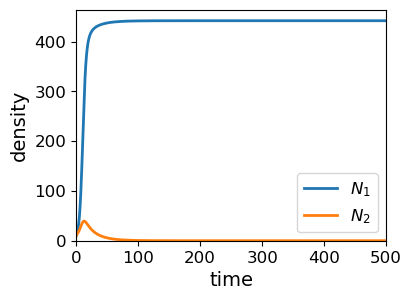

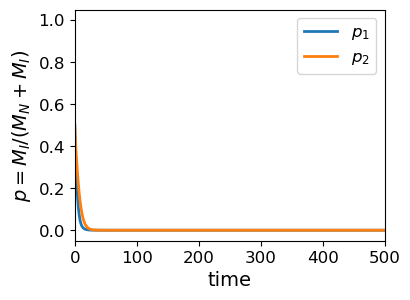

region_02: species2_excluded | sp1:polymorphic; s=0.70, rho=0.90, time=1000, equilibrium distance=1.35e-07


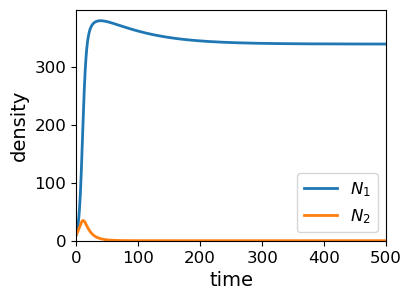

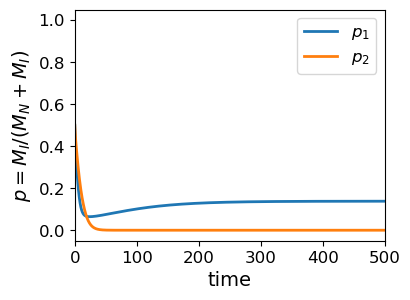

region_03: species2_excluded | sp1:1; s=0.10, rho=0.90, time=2000, equilibrium distance=1.45e-11


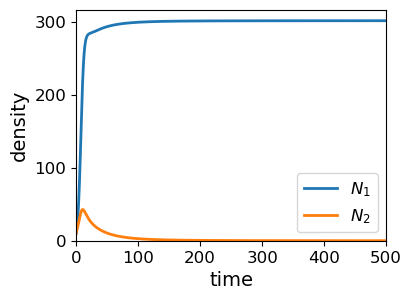

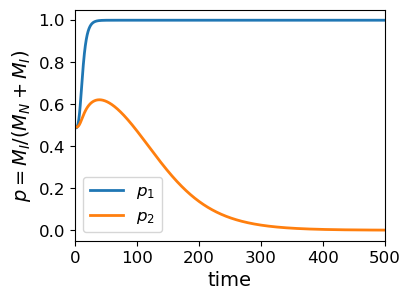

region_04: sp1:0 | sp2:0; s=0.90, rho=0.40, time=1000, equilibrium distance=1.10e-14


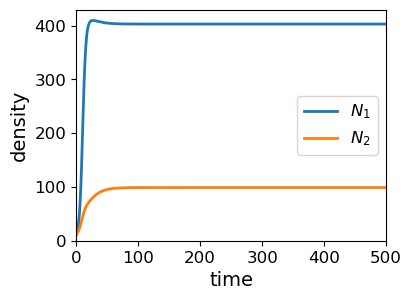

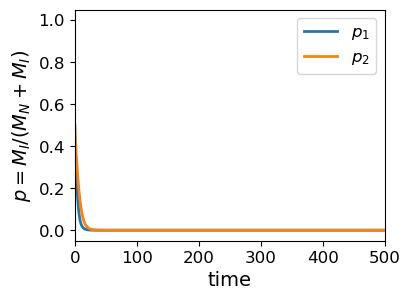

region_05: sp1:1 | sp2:0; s=0.20, rho=0.90, time=2000, equilibrium distance=1.09e-07


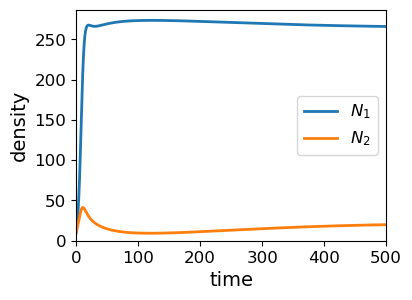

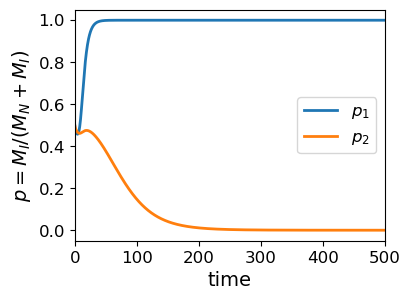

region_06: sp1:1 | sp2:1; s=0.20, rho=0.30, time=1000, equilibrium distance=1.35e-14


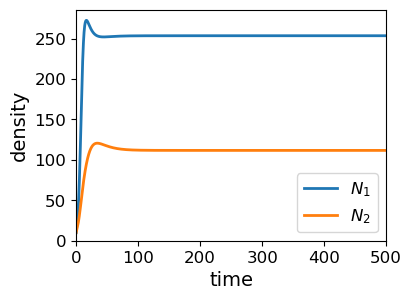

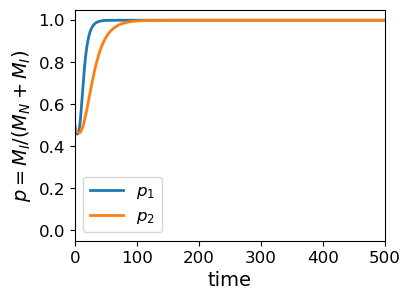

region_07: sp1:1 | sp2:polymorphic; s=0.30, rho=0.80, time=1000, equilibrium distance=2.25e-08


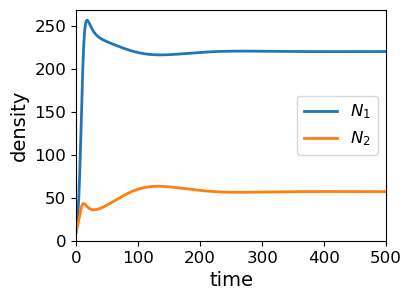

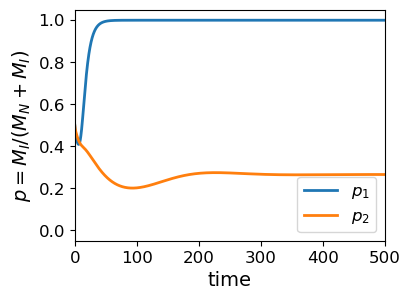

region_08: sp1:polymorphic | sp2:0; s=0.60, rho=0.90, time=1000, equilibrium distance=6.57e-07


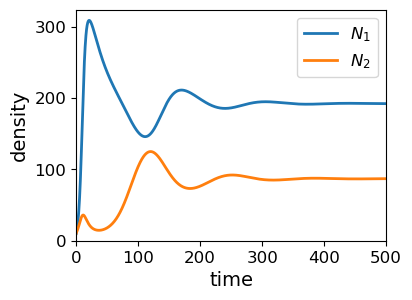

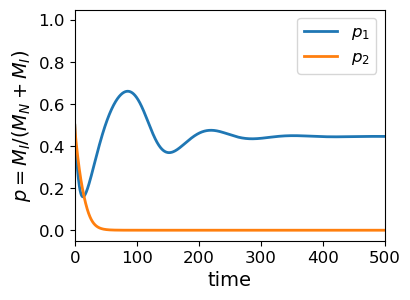

region_09: sp1:polymorphic | sp2:polymorphic; s=0.60, rho=0.20, time=2000, equilibrium distance=1.38e-06


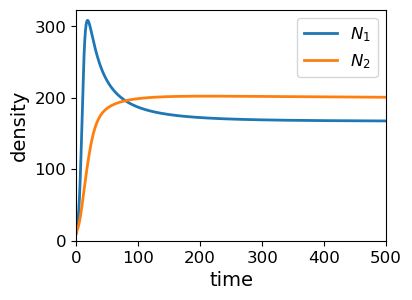

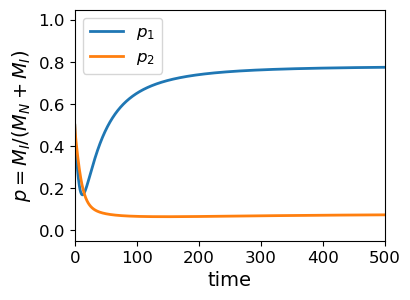

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.ndimage import distance_transform_edt

# Separate trajectories for each region of the preceding (s, rho) diagram.
# Shared initial conditions: N1=N2=10, p1=p2=0.5, five equally
# frequent female states, and equal total male and female densities.
# These trajectories describe outcomes from this initial condition, not basin sizes.
region_scan = phase_diagram_2sp_s_rho_scan
region_s = np.asarray(region_scan["s_values"])
region_rho = np.asarray(region_scan["rho_values"])
region_ecology = np.asarray(region_scan["ecology_labels"], dtype=object)
region_labels = np.asarray(region_scan["evolution_labels"], dtype=object).copy()
for i, j in np.argwhere(region_ecology == "species1_only"):
    p = region_scan["selected_equilibria"][i][j]["p1"]
    state = "0" if p <= 1e-6 else "1" if p >= 1-1e-6 else "polymorphic"
    region_labels[i, j] = f"species2_excluded | sp1:{state}"

region_order = [
    "species2_excluded | sp1:0",
    "species2_excluded | sp1:polymorphic",
    "species2_excluded | sp1:1",
    "sp1:0 | sp2:0",
    "sp1:1 | sp2:0",
    "sp1:1 | sp2:1",
    "sp1:1 | sp2:polymorphic",
    "sp1:polymorphic | sp2:0",
    "sp1:polymorphic | sp2:polymorphic",
]
region_dynamics_results = {}
REGION_DISPLAY_END = 500.0
axis_tick_fontsize = 12
axis_label_fontsize = 14


def region_endpoint_label(y):
    densities = np.array([y[:7].sum(), y[7:].sum()])
    p = [y[6]/(y[5]+y[6]) if y[5]+y[6] > 1e-10 else np.nan,
         y[13]/(y[12]+y[13]) if y[12]+y[13] > 1e-10 else np.nan]
    def state(value):
        return "0" if value < 1e-3 else "1" if value > 1-1e-3 else "polymorphic"
    if densities[1] < 1e-5 and densities[0] > 1e-5:
        return f"species2_excluded | sp1:{state(p[0])}"
    if densities.min() > 1e-5:
        return f"sp1:{state(p[0])} | sp2:{state(p[1])}"
    return "other_outcome"


for number, label in enumerate(region_order, start=1):
    mask = region_labels == label
    if not np.any(mask):
        raise ValueError(f"Region absent from scan: {label}")
    interior_distance = distance_transform_edt(np.pad(mask, 1))[1:-1, 1:-1]
    # Prefer simple decimal values within the region; keep some distance
    # from class boundaries where possible. Thin regions can require 0.01 steps.
    candidates = np.argwhere(mask)
    max_distance = float(interior_distance.max())
    safe = candidates[interior_distance[mask] >= min(2.0, max_distance)]
    def decimal_complexity(value):
        if np.isclose(value, 0.0) or np.isclose(value, 1.0):
            return 0
        if np.isclose(value * 10, round(value * 10)):
            return 1
        if np.isclose(value * 20, round(value * 20)):
            return 2
        return 3
    def representative_score(point):
        row, column = point
        cs = decimal_complexity(region_s[row])
        cr = decimal_complexity(region_rho[column])
        return (max(cs, cr), cs + cr, -interior_distance[row, column],
                abs(region_s[row] - 0.5) + abs(region_rho[column] - 0.5))
    i, j = min(safe, key=representative_score)
    eq = region_scan["selected_equilibria"][i][j]
    region_params = dict(region_scan.get("params", params),
                         s1=float(region_s[i]), s2=float(region_s[i]),
                         rho12=float(region_rho[j]), rho21=float(region_rho[j]))
    # Each species has five female compartments of density 1 and two
    # male types of density 2.5: female total=male total=5, N=10, p=0.5.
    initial = np.tile(np.array([1., 1., 1., 1., 1., 2.5, 2.5]), 2)
    horizon = 1000.0
    while True:
        trajectory = solve_ivp(
            lambda time, y: two_species_ecoevo_rhs(time, y, region_params),
            (0.0, horizon), initial, method="LSODA",
            t_eval=np.unique(np.r_[np.linspace(0.0, REGION_DISPLAY_END, 2000),
                                   np.linspace(REGION_DISPLAY_END, horizon, 2000)]),
            rtol=1e-8, atol=1e-10,
        )
        if not trajectory.success:
            raise RuntimeError(trajectory.message)
        endpoint = trajectory.y[:, -1]
        distance = np.max(np.abs(endpoint - eq["y_star"])) / max(1.0, np.max(eq["y_star"]))
        matches = region_endpoint_label(endpoint) == label
        if matches and distance < 1e-4:
            break
        if horizon >= 16000:
            raise RuntimeError(f"Trajectory did not reach target {label}: {region_endpoint_label(endpoint)}")
        horizon *= 2
    values = np.maximum(trajectory.y, 0.0)
    populations = [values[:7].sum(axis=0), values[7:].sum(axis=0)]
    frequencies = []
    for offset in [0, 7]:
        males = values[offset+5] + values[offset+6]
        # Keep plotting the frequency while the male denominator is positive.
        frequencies.append(np.divide(values[offset+6], males,
                           out=np.full_like(males, np.nan),
                           where=males > 0.0))
    slug = f"region_{number:02d}"
    fig_N, ax_N = plt.subplots(figsize=(4, 3))
    ax_N.plot(trajectory.t, populations[0], label=r'$N_1$', lw=2)
    ax_N.plot(trajectory.t, populations[1], label=r'$N_2$', lw=2)
    ax_N.set_xlim(0.0, REGION_DISPLAY_END)
    ax_N.set_ylim(bottom=-0.05)
    ax_N.set_xlabel('time', fontsize=axis_label_fontsize)
    ax_N.set_ylabel('density', fontsize=axis_label_fontsize)
    ax_N.tick_params(axis='both', labelsize=axis_tick_fontsize)
    ax_N.legend(frameon=True, fontsize=axis_tick_fontsize)

    fig_p, ax_p = plt.subplots(figsize=(4, 3))
    ax_p.plot(trajectory.t, frequencies[0], label=r'$p_1$', lw=2)
    ax_p.plot(trajectory.t, frequencies[1], label=r'$p_2$', lw=2)
    ax_p.set_xlim(0.0, REGION_DISPLAY_END)
    ax_p.set_ylim(-0.05, 1.05)
    ax_p.set_xlabel('time', fontsize=axis_label_fontsize)
    ax_p.set_ylabel(r'$p = M_I / (M_N + M_I)$', fontsize=axis_label_fontsize)
    ax_p.tick_params(axis='both', labelsize=axis_tick_fontsize)
    ax_p.legend(frameon=True, fontsize=axis_tick_fontsize)
    region_dynamics_results[label] = {
        "region": number, "params": region_params, "y0": initial,
        "trajectory": trajectory, "target_equilibrium": eq,
        "endpoint_label": region_endpoint_label(endpoint),
        "equilibrium_relative_distance": distance,
        "population_figure": fig_N, "evolution_figure": fig_p,
    }
    print(f"{slug}: {label}; s={region_s[i]:.2f}, rho={region_rho[j]:.2f}, "
          f"time={horizon:g}, equilibrium distance={distance:.2e}")
    plt.show()

